# Global drought map

This script is using a sample from the ERA5--Drought data set from the European Centre for Medium-range Weather Forecasts (ECMWF) and plots a global map of the dataset. 
The output of this notebook is published as Figure 1 in 
> Keune, J., F. Di Giuseppe, C. Barnard, E. Damasio da Costa, and F. Wetterhall (2025): ERA5--Drought: Global drought indicators based on ECMWF reanalysis. Sci Data 12, 616 (2025). https://doi.org/10.1038/s41597-025-04896-y.

## Setup & Settings

#### Load libraries

In [1]:
import os 
import sys
import netCDF4 as nc4
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import cartopy
import cartopy.feature as feature
import cartopy.io.shapereader as shapereader

#### Plot settings

In [2]:
mylevels     = [-10000,-1000,-2,-1.5,-1,1,1.5,2,1000]
mycollisthex = ['#bebebe','#663300','#8c6640','#b29980','#ffffff','#99b280','#668c40','#336600']
legnames     = ["masked","extremely dry", "severely dry", "moderately dry", "near normal", "moderately wet", "severely wet", "extremely wet"]

#### Some helpful functions

In [3]:
def hex2rgb(hexs):
   return tuple(int(hexs[i:i+2], 16)/255 for i in (0, 2, 4))

3


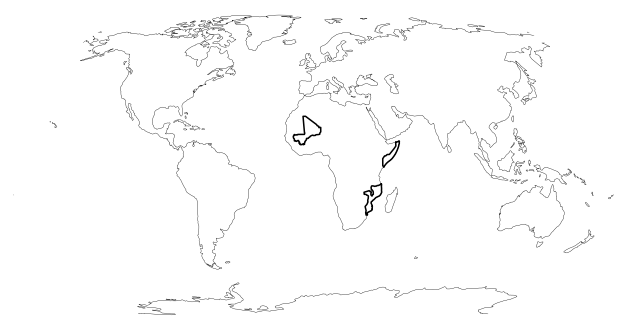

In [4]:
countries = shapereader.natural_earth(resolution='110m',
                              category='cultural',
                              name='admin_0_countries')

plt.figure(figsize=(9, 4));
ax = plt.axes(projection=ccrs.Robinson(), frameon=False);

highlight_countries = ["Mozambique", "Somalia", "Mali"]
print(len(highlight_countries))
ax.coastlines(color='black', lw=0.25)
for country in shapereader.Reader(countries).records():
    if country.attributes['ADMIN'] in highlight_countries:
        #print(country)
        ax.add_geometries([country.geometry], crs=ccrs.PlateCarree(), edgecolor='black', facecolor="None", linewidth=1.1)
#    if country.attributes['FORMAL_EN'] in highlighted_countries:
#        ax.plot(country.geometry)

#### Function to plot global map

In [5]:
def worldmap_drought(data_2d, 
                     collist_hex, 
                     levels,
                     legnames,
                     plot_borders=False,
                     highlight_countries=[],
                     myextent = [-170000, 180, -50, 82],#[x0, x1, y0, y1],
                     figx=9, figy=4,
                     figname="figures/SPEI12_global_19000000.png",
                     latlines=[-30,30], plot_latlines=False, mytitle=""):

    plt.figure(figsize=(figx, figy));
    #plt.box(False)
    ax = plt.axes(projection=ccrs.Robinson(), frameon=False);
    ax.coastlines(color='black', lw=0.25)
    data_2d.plot(ax=ax, transform=ccrs.PlateCarree(),
                              x='lon', y='lat',
                              add_colorbar=False,
                              colors=collist_hex,
                              levels=levels,
                              vmin=-3, vmax=3)
    ax.set_title(mytitle)

    # horizontal lat-lines
    if plot_latlines:
        geodetic = ccrs.Geodetic()
        robinson = ccrs.Robinson()
        for ilat in latlines:
            ilon_1, ilat_1 = robinson.transform_point(-179, ilat, geodetic)
            ilon_2, ilat_2 = robinson.transform_point(+179, ilat, geodetic)
            ax.plot([ilon_1, ilon_2], [ilat_1, ilat_2], color='grey', linewidth=0.5, transform=robinson, linestyle=':')

    ax.set_extent(myextent) # (x0, x1, y0, y1)
    #ax.set_extent([-170000, 180, -50, 82]) # (x0, x1, y0, y1)
    if plot_borders:
        ax.add_feature(cartopy.feature.BORDERS, color='black', lw=0.3)
    if len(highlight_countries) != 0:
        countries = shapereader.natural_earth(resolution='110m', category='cultural', name='admin_0_countries')
        for country in shapereader.Reader(countries).records():
            if country.attributes['ADMIN'] in highlight_countries:
                #country_reproj = country.to_crs(ccrs.Robinson()).geometry
                ax.add_geometries([country.geometry], edgecolor='black', facecolor="None", linewidth=0.85, crs=ccrs.PlateCarree())
        
    legend_elements = []
    for i in range(len(legnames)):
        legend_elements.append(Line2D([0], [0], marker='s', color='w', label=legnames[i], markerfacecolor=hex2rgb(collist_hex[i][1:]), markersize=8))
    plt.legend(handles=legend_elements, fontsize="8", loc ="lower left", ncol=1)

    plt.tight_layout()
    #plt.subplots_adjust(bottom=0.025, hspace=0.5, wspace=0.05)
    plt.savefig(figname, format=None, metadata=None,
                bbox_inches=None, pad_inches=0.1, dpi=300,
                facecolor='auto', edgecolor='auto',
                backend=None)
    plt.show()

## Drought indicator

### Settings

In [42]:
ref_syyyy = 1991
ref_eyyyy = 2020
indicator = "SPEI"
#indicator = "SPI"
window    = 24
yyyy      = 2025
mm        = "08"
dataset   = "era5t"
stream    = "moda"
distribut = "genlogistic"
#distribut = "gamma"
ifile_name= f"{indicator}{window}_{distribut}_global_{dataset}_{stream}_ref{ref_syyyy}to{ref_eyyyy}_{yyyy}{str(mm).zfill(2)}.nc"
# old version
#ipath     = "/ec/vol/centaur/nejk/drought_monitor"
#ifile     = f"{ipath}/{indicator.lower()}/{indicator.lower()}{window}/{ifile_name}"
# new versions
#ipath     = f"/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/era5/{yyyy}{mm}01/hr"
ipath     = f"/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/era5t/{yyyy}{mm}01/hr"
ifile     = f"{ipath}/{ifile_name}"
print(ifile)

/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/era5t/20250801/hr/SPEI24_genlogistic_global_era5t_moda_ref1991to2020_202508.nc


### Read drought indicator

In [43]:
drought_2d = xr.open_dataset(ifile)
print(drought_2d)

<xarray.Dataset> Size: 8MB
Dimensions:  (time: 1, lat: 721, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 8B 2025-08-01T06:00:00
  * lat      (lat) float64 6kB 90.0 89.75 89.5 89.25 ... -89.5 -89.75 -90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    SPEI24   (time, lat, lon) float64 8MB ...
Attributes: (12/17)
    title:                   SPEI24
    description:             Drought Index: Standardized Drought Index calcul...
    Conventions:             CF-1.8
    history:                 Created 03/09/2025 00:12:31 using DRYFALL.
    institution:             European Centre for Medium-Range Weather Forecasts
    source:                  DRYFALL v1.0
    ...                      ...
    extent:                  -180,-90,180,90
    resolution:              0.25x0.25
    climate_start_date:      1991-01-01
    climate_end_date:        2020-12-31
    frequency:               Monthly
    contact_person:          support@ecmwf.i

### Apply masks

#### Mask NaNs

In [44]:
drought_2d_masked = xr.where(drought_2d[f'{indicator}{window}'] == -9999, np.nan, drought_2d[f'{indicator}{window}'])
#print(drought_2d_masked)

#### Mask barren areas

In [45]:
vfile = "/home/nejk/code/dryfall_oper/helpers_oper/barren_mask.nc"
bmask = xr.open_dataset(vfile)
#bmask['barren_mask'].plot()

In [46]:
drought_2d_masked = xr.where( (bmask['barren_mask'][0,:,:] == 1) & (~np.isnan(drought_2d_masked)) , -9999, drought_2d_masked)

## Plot global map

In [47]:
print(f"figures/{indicator}{window}_{yyyy}{str(mm).zfill(2)}.pdf")

figures/SPEI24_202508.pdf


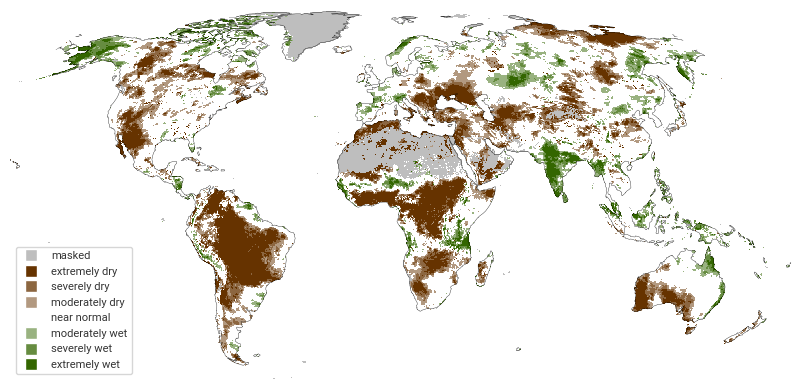

In [48]:
worldmap_drought(drought_2d_masked, 
                 collist_hex = mycollisthex, 
                 #levels = [-10000].append(mylevels),
                 #legnames = ["masked"].append(legnames),
                 levels = [-10000,-1000,-2,-1.5,-1,1,1.5,2,1000],
                 legnames = ["masked","extremely dry", "severely dry", "moderately dry", "near normal", "moderately wet", "severely wet", "extremely wet"],
                 plot_borders=False,
                 myextent = [-170000, 180, -50, 82],
                 #highlight_countries = ["Mozambique", "Somalia", "Mali"],
                 #figname = f"figures/{indicator}{window}_{yyyy}{str(mm).zfill(2)}_CENTAUR.png",
                 figname = f"figures/{indicator}{window}_{yyyy}{str(mm).zfill(2)}.png",
                 latlines = [-30,30], 
                 plot_latlines =False, 
                 mytitle       = "")

### Plot European map

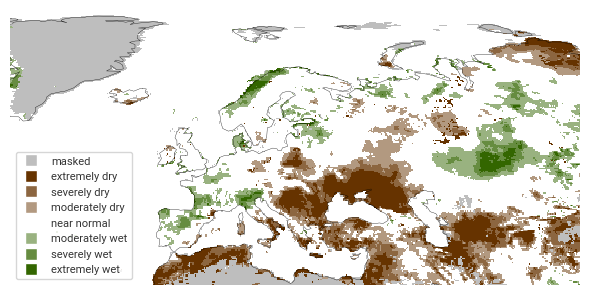

In [49]:
worldmap_drought(drought_2d_masked, 
                 collist_hex = mycollisthex, 
                 #levels = [-10000].append(mylevels),
                 #legnames = ["masked"].append(legnames),
                 levels = [-10000,-1000,-2,-1.5,-1,1,1.5,2,1000],
                 legnames = ["masked","extremely dry", "severely dry", "moderately dry", "near normal", "moderately wet", "severely wet", "extremely wet"],
                 plot_borders=False,
                 myextent = [-130000, 80, 30, 82],
                 figx=6, figy=4,
                 #myextent = [-906977, 70, 30, 72],
                 #figname = f"figures/{indicator}{window}_{yyyy}{str(mm).zfill(2)}_europe.pdf",
                 figname = f"figures/{indicator}{window}_{yyyy}{str(mm).zfill(2)}_europe.png",
                 latlines = [-30,30], 
                 plot_latlines =False, 
                 mytitle       = "")

In [50]:
# get Robinson lat/lon extent of Europe
geodetic = ccrs.Geodetic()
robinson = ccrs.Robinson()
ilon_1, ilat_1 = robinson.transform_point(-10, 30, geodetic)
ilon_2, ilat_2 = robinson.transform_point(60, 75, geodetic)
print(ilat_1)
print(ilat_2)
print(ilon_1)
print(ilon_2)
#    ax.plot([ilon_1, ilon_2], [ilat_1, ilat_2], color='grey', linewidth=0.5, transform=robinson, linestyle=':')


3208557.6115038935
7707438.096865358
-906977.7573554792
3816109.0631607655
